# From ratios to metres: reconstructing the absolute pattern of a blast and testing it against the paper

**Question:** Can the published ratios be turned into metres, and how do we know the conversion is right?

**Level 2: The method in practice** · Needs: 01-the-data/01-the-corpus-and-the-cases · Reading time: about 25 minutes

## Objectives

The classical mean-size equation needs a rock volume in cubic metres and an explosive mass in kilograms, but the published corpus gives only dimensionless ratios. This notebook asks whether the ratios can be turned into metres and, because a wrong conversion would corrupt every classical prediction without raising any error, how we can know the conversion is right.

By the end you will have:

- reconstructed the pattern of one blast from a registered hole diameter and the printed ratios, with the engine and with plain arithmetic;
- rebuilt the 91 blasts of the nine sites whose scale is known and seen the lengths and rock volumes they imply;
- run the engine's check against the 15 lengths the source prose states, and read where each reconstruction sits inside its stated range;
- measured the power of that check by replacing the Soma diameter with other values, and seen what a guessed diameter would do at Miami, the site that publishes none.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, sets the plotting style and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, the pinned versions, the plotting style and one helper that renders a table
import dataclasses
from importlib.metadata import version
from unittest.mock import patch

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

One source, read from the engine:

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus, and the site narratives (hole diameters, bench heights, burdens, spacings) | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the table and the `SITE_GEOMETRY` registry inside the `blastfrag` wheel |

Each registry entry stores the hole diameter of a site, how it was obtained (quoted from the paper, derived from a stated length, or not published) and the dimensional statements the paper makes about that site, as ranges in metres.

## Method

The ratios of a blast are defined against its burden `B` and its hole diameter `D`, so one known length, the diameter, fixes every other length:

- burden `B = (B/D) * D`
- spacing `S = (S/B) * B`
- bench height `H = (H/B) * B`
- stemming `T = (T/B) * B`

The rock volume per hole is `V = B * S * H` and the explosive mass is `Q = Pf * V`, with `Pf` the powder factor that the corpus prints directly (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957). The hole diameter is the only quantity the table cannot give, so the engine keeps a registry with, for each site, the diameter the paper's prose states, how it was obtained and the lengths in metres that the prose states about the site. The registry is the one place where judgement enters, and the rest of the notebook asks how far that judgement can be trusted.

### Step 1: the registry

The cell prints, for every site, the registered diameter, whether it was quoted from the paper, derived from a stated length or not published at all, how many lengths in metres the paper states for the site (the statements the reconstruction will be tested against) and how many of its blasts have a scale. Look for the sites that are not simply quoted.

In [2]:
# The registry the engine ships: each site's hole diameter, where it came from and what the paper states about it
train = bf.load_training_corpus()
sites = sorted({b.site for b in train})
rows = []
for site in sites:
    geometry = bf.SITE_GEOMETRY[site]
    members = [b for b in train if b.site == site]
    diameter = "-" if geometry.hole_diameter_mm is None else f"{geometry.hole_diameter_mm:g}"
    kind = "quoted"
    if geometry.diameter_source.startswith("DERIVED"):
        kind = "derived"
    elif geometry.diameter_source.startswith("NOT PUBLISHED"):
        kind = "not published"
    scaled = sum(bf.has_absolute_geometry(b) for b in members)
    rows.append((site, diameter, kind, len(geometry.narrative), f"{scaled} of {len(members)}"))
header = ["site", "D (mm)", "source of D", "stated lengths",
          "blasts with a scale"]
show_table(header, rows, left=3)
print("source of the derived diameter:", bf.SITE_GEOMETRY["Reocin-UG"].diameter_source[:150], "...")

| site | D (mm) | source of D | stated lengths | blasts with a scale |
|:---|:---|:---|---:|---:|
| Akdaglar | 89 | quoted | 1 | 22 of 22 |
| Dongri-Buzurg | 100 | quoted | 3 | 9 of 9 |
| Enusa | 165 | quoted | 1 | 12 of 12 |
| Miami | - | not published | 0 | 0 of 6 |
| Mrica | 76 | quoted | 1 | 11 of 11 |
| Murgul | 165 | quoted | 3 | 7 of 7 |
| Ozmert | 89 | quoted | 2 | 7 of 7 |
| Reocin | 229 | quoted | 1 | 10 of 10 |
| Reocin-UG | 91.2 | derived | 1 | 6 of 6 |
| Soma | 210 | quoted | 2 | 7 of 7 |

source of the derived diameter: DERIVED, not published. The paper states an 18 m bench for the Reocin underground mine and gives no diameter. Inverting B = H / (H/B) and then D = B / ...


Eight of the ten diameters are quoted from the paper's prose. Reocin-UG, at 91.2 mm, is derived from a stated bench height, and the printed source line says so; Miami has no diameter. The paper states 15 lengths in metres across the other nine sites, and Miami has none, so nothing can test it. The table says where each diameter came from, not that it is right: the next steps test it. The 91 blasts with a scale are all the blasts of the nine sites that have a diameter.

### Step 2: one blast

Blast `En1` of Enusa, registered at 165 mm, shows the whole chain. The cell asks the engine for its pattern with `reconstruct_pattern` and lays out, in a table, which number each length comes from: the burden is a ratio of the diameter, and the spacing, the bench height and the stemming are ratios of the burden. Then the volume is the product of three lengths and the explosive mass follows from the powder factor.

In [3]:
# Reconstruct blast En1 with the engine and lay out which registered number each length comes from
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rows = [
    ("hole diameter D", "registry", f"{pattern.hole_diameter_mm / 1000:.4f}"),
    ("burden B", f"{blast.B_over_D} x D", f"{pattern.burden_m:.4f}"),
    ("spacing S", f"{blast.S_over_B} x B", f"{pattern.spacing_m:.4f}"),
    ("bench height H", f"{blast.H_over_B} x B", f"{pattern.bench_height_m:.4f}"),
    ("stemming T", f"{blast.T_over_B} x B", f"{pattern.stemming_m:.4f}"),
    ("rock volume V (m3)", "B x S x H", f"{pattern.rock_volume_m3:.2f}"),
    ("explosive mass Q (kg)", f"Pf x V, Pf = {pattern.powder_factor_kg_m3}", f"{pattern.charge_mass_kg:.2f}"),
]
show_table(["quantity", "comes from", "value (m)"], rows, left=2)

| quantity | comes from | value (m) |
|:---|:---|---:|
| hole diameter D | registry | 0.1650 |
| burden B | 27.27 x D | 4.4996 |
| spacing S | 1.24 x B | 5.5794 |
| bench height H | 1.33 x B | 5.9844 |
| stemming T | 0.78 x B | 3.5096 |
| rock volume V (m3) | B x S x H | 150.24 |
| explosive mass Q (kg) | Pf x V, Pf = 0.48 | 72.11 |

The burden is 27.27 diameters, 4.4996 m, and every other length is one more multiplication. The three lengths of the volume all descend from the diameter, so an error in the diameter does not stay in one length: the volume grows with the cube of it, and the explosive mass with the volume. Here the powder factor of 0.48 kg/m3 turns a rock volume of 150.24 m3 into 72.11 kg of explosive. The table shows the chain; it does not show that 165 mm is the right starting point.

### Reproduction check: the arithmetic by hand

The formulas are four multiplications, so they can be done without the engine. The cell recomputes the four lengths from the registered diameter and the printed ratios and compares them with the engine's pattern. This is the notebook's only reproduction check: it establishes that the engine adds no hidden step, such as a subdrill allowance, and not that the diameter is right.

In [4]:
# The four lengths again from the registered diameter and the printed ratios, with plain arithmetic
diameter_m = bf.SITE_GEOMETRY[blast.site].hole_diameter_mm / 1000
burden = blast.B_over_D * diameter_m
by_hand = [burden, blast.S_over_B * burden, blast.H_over_B * burden, blast.T_over_B * burden]
from_engine = [pattern.burden_m, pattern.spacing_m, pattern.bench_height_m, pattern.stemming_m]
print("by hand equals the engine to 1e-9 m:", np.allclose(by_hand, from_engine, rtol=0, atol=1e-9))

by hand equals the engine to 1e-9 m: True


The hand arithmetic and the engine agree to 1e-9 m, so for this blast the reconstruction is exactly the product of the printed ratios and the registered diameter, with no allowance for subdrilling or drill deviation. What the check cannot do is say whether 165 mm is the diameter that was drilled: that needs evidence from outside the arithmetic, which is what Step 4 supplies.

### Step 3: the whole corpus

The cell reconstructs every blast whose scale is known (`has_absolute_geometry` selects them) and draws what the classical equation will see: burden against bench height on the left, and on the right the rock volume that one hole breaks. The values are in metres and cubic metres, so a reader who knows a mine can judge them.

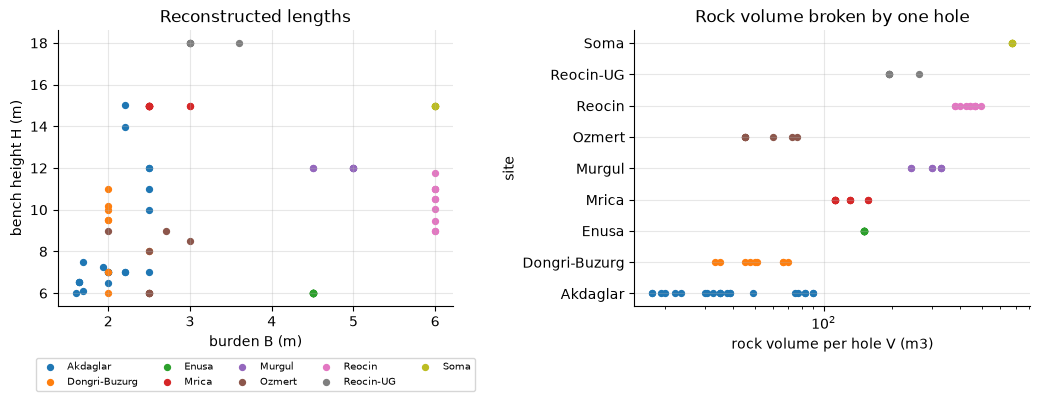

blasts with a scale: 91 | V: 17.6 to 675 m3
largest volume over the smallest: 38


In [5]:
# Reconstruct every blast with a known scale, then draw burden against bench height and the rock volume per hole
patterns = {b.blast_id: bf.reconstruct_pattern(b) for b in train if bf.has_absolute_geometry(b)}
scaled_sites = [s for s in sites if any(b.site == s and b.blast_id in patterns for b in train)]
colors = plt.cm.tab10(np.arange(len(scaled_sites)))
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for position, (color, site) in enumerate(zip(colors, scaled_sites)):
    members = [patterns[b.blast_id] for b in train if b.site == site and b.blast_id in patterns]
    left.scatter([p.burden_m for p in members], [p.bench_height_m for p in members], s=18, color=color, label=site)
    right.scatter([p.rock_volume_m3 for p in members], [position] * len(members), s=18, color=color)
left.set_xlabel("burden B (m)")
left.set_ylabel("bench height H (m)")
left.set_title("Reconstructed lengths")
left.legend(fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17))
right.set_xscale("log")
right.xaxis.set_minor_formatter(plt.NullFormatter())
right.set_yticks(range(len(scaled_sites)), scaled_sites)
right.set_xlabel("rock volume per hole V (m3)")
right.set_ylabel("site")
right.set_title("Rock volume broken by one hole")
fig.tight_layout()
plt.show()
volumes = [p.rock_volume_m3 for p in patterns.values()]
print(f"blasts with a scale: {len(patterns)} | V: {min(volumes):.1f} to {max(volumes):.0f} m3")
print(f"largest volume over the smallest: {max(volumes) / min(volumes):.0f}")

The 91 reconstructed blasts break between 17.6 and 675 m3 of rock per hole, a ratio of 38. The left panel shows that sites fire in families: all the blasts of Enusa share one burden and one bench height, and so do those of Soma, Reocin uses one burden with bench heights from 9 to 11.76 m, and Akdaglar varies both. The right panel shows that scale differs between sites far more than inside them, which is what the dimensionless ratios hid. The figure shows that the lengths are plausible bench dimensions if each registered diameter is right; it does not show that they are right.

### Step 4: test the reconstruction against the paper

If a diameter were wrong, every length of its site would be wrong by the same factor. The paper's prose states a few lengths directly (for example "the bench height was 6 m"). `verify_reconstruction` reconstructs every blast of a site and requires each stated range to contain the reconstructed range, allowing only the slack that the two-decimal printing of the ratios produces; it raises an `AssertionError` on any violation, so it also works as a gate. The first cell lists every statement it tested, and the second draws each one as the range the paper states against the range the registry reconstructs.

In [6]:
# Run the engine's own check on the whole corpus and list every dimensional statement of the paper it tested
report = bf.verify_reconstruction(train)
rows = []
for site, entry in report.items():
    for check in entry.get("checks", []):
        stated = f"{check['stated'][0]:g} to {check['stated'][1]:g}"
        got = f"{check['reconstructed'][0]:g} to {check['reconstructed'][1]:g}"
        rows.append((site, check["quantity"], stated, got, "yes" if check["ok"] else "no"))
header = ["site", "quantity", "paper states (m)",
          "reconstructed (m)", "met"]
show_table(header, rows, left=2)
print("statements tested:", len(rows), "| met:", sum(r[4] != "no" for r in rows))

| site | quantity | paper states (m) | reconstructed (m) | met |
|:---|:---|---:|---:|---:|
| Akdaglar | burden_m | 1.5 to 2.6 | 1.6 to 2.5 | yes |
| Dongri-Buzurg | bench_height_m | 6 to 11 | 6 to 11 | yes |
| Dongri-Buzurg | burden_m | 2 to 2.5 | 2 to 2.5 | yes |
| Dongri-Buzurg | spacing_m | 1.8 to 3.5 | 2.5 to 3.5 | yes |
| Enusa | bench_height_m | 6 to 6 | 5.984 to 5.984 | yes |
| Mrica | bench_height_m | 10 to 15 | 14.998 to 14.999 | yes |
| Murgul | bench_height_m | 12 to 12.05 | 11.999 to 12.014 | yes |
| Murgul | burden_m | 4.5 to 5 | 4.5 to 5 | yes |
| Murgul | spacing_m | 4.5 to 5.5 | 4.5 to 5.499 | yes |
| Ozmert | burden_m | 2 to 3 | 2 to 3 | yes |
| Ozmert | spacing_m | 2.5 to 3 | 2.5 to 3 | yes |
| Reocin | bench_height_m | 9 to 11.8 | 9 to 11.76 | yes |
| Reocin-UG | bench_height_m | 18 to 18 | 17.997 to 17.998 | yes |
| Soma | bench_height_m | 15 to 15 | 14.999 to 14.999 | yes |
| Soma | spacing_m | 7.5 to 7.5 | 7.5 to 7.5 | yes |

statements tested: 15 | met: 15


All 15 statements are met, across nine sites. They are not equally demanding. Some are single values, such as the 6 m bench at Enusa, which reconstructs to 5.984 m; others are wide, such as the 10 to 15 m bench at Mrica, which a wrong diameter could still fit. The Mrica reconstruction, 14.998 m, sits at the top of its range, which is informative in itself. The table gives the verdicts; the figure that follows shows how much room each statement leaves.

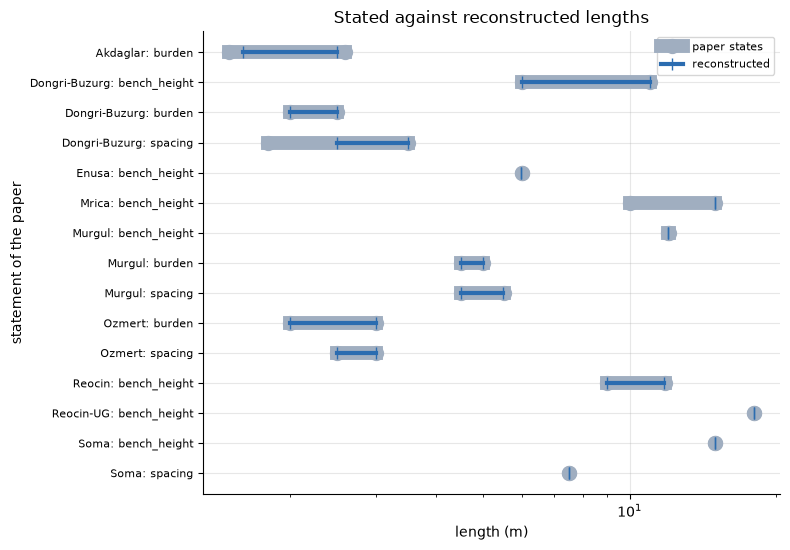

In [7]:
# Each statement as a grey bar (what the paper states) and a blue bar (what the registry reconstructs), in metres
checks = [(site, check) for site, entry in report.items() for check in entry.get("checks", [])]
labels = [f"{site}: {check['quantity'].removesuffix('_m')}" for site, check in checks]
stated_style = dict(color="#a0aec0", lw=10, marker="o", ms=10)
built_style = dict(color="#2b6cb0", lw=3, marker="|", ms=9)
fig, ax = plt.subplots(figsize=(8, 5.6))
for row, (site, check) in enumerate(checks):
    ax.plot(check["stated"], [row, row], **stated_style)
    ax.plot(check["reconstructed"], [row, row], **built_style)
ax.plot([], [], label="paper states", **stated_style)
ax.plot([], [], label="reconstructed", **built_style)
ax.set_xscale("log")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(range(len(checks)), labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("length (m)")
ax.set_ylabel("statement of the paper")
ax.set_title("Stated against reconstructed lengths")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Each row is one statement: the grey bar is the range the paper states and the blue bar is what the registry reconstructs, on a logarithmic axis in metres. Every blue bar lies inside its grey bar. Where the grey bar is a single dot (the benches of Enusa, Reocin-UG and Soma, and the spacing of Soma) the paper states one value and the reconstruction lands on it, which is the most demanding case. Where the grey bar is wide, as for Mrica and Akdaglar, the check is weak. The figure cannot say how many other diameters would also pass; the next step counts them.

### Step 5: does the check have power?

A check that cannot fail proves nothing. The Soma narrative is the useful test: it states two lengths, a 15 m bench and a 7.5 m spacing, and the registry records an unresolved conflict about its burden, because the paper also quotes a burden and a diameter that the ratio table cannot hold together. The cell replaces the Soma diameter with candidates from 150 to 280 mm, with a fine grid around the registered value, reconstructs the lengths for each and counts how many of the two stated lengths the engine's check accepts, calling `verify_reconstruction` once per statement. `patch.dict` places a candidate in the registry only inside its `with` block, so nothing leaks into later cells.

In [8]:
# Try other Soma hole diameters: reconstruct its lengths and count which of its two stated lengths each one satisfies
soma = [b for b in train if b.site == "Soma"]
registered = bf.SITE_GEOMETRY["Soma"]
sweep = []
grid = np.unique(np.concatenate([np.arange(150.0, 280.1, 2.0), np.arange(208.0, 212.01, 0.1)]).round(1))
for diameter in grid:
    candidate = dataclasses.replace(registered, hole_diameter_mm=float(diameter))
    with patch.dict(bf.SITE_GEOMETRY, {"Soma": candidate}):
        patterns_soma = [bf.reconstruct_pattern(b) for b in soma]
    met = 0
    for statement in registered.narrative:
        single = dataclasses.replace(candidate, narrative=(statement,))
        with patch.dict(bf.SITE_GEOMETRY, {"Soma": single}):
            try:
                bf.verify_reconstruction(soma)
                met += 1
            except AssertionError:
                pass
    sweep.append((diameter, patterns_soma[0].bench_height_m, patterns_soma[0].spacing_m, met))
passing = [d for d, _, _, met in sweep if met == len(registered.narrative)]
print("statements to satisfy:", registered.narrative)
print(f"diameters that satisfy both (mm): {min(passing):g} to {max(passing):g}")
print(f"width of that window (mm): {max(passing) - min(passing):.1f}")
print(f"registered diameter (mm): {registered.hole_diameter_mm:g}")
print("registry note on Soma:", registered.note)

statements to satisfy: (('bench_height_m', 15.0, 15.0), ('spacing_m', 7.5, 7.5))
diameters that satisfy both (mm): 209.6 to 210.4
width of that window (mm): 0.8
registered diameter (mm): 210
registry note on Soma: UNRESOLVED SOURCE CONFLICT. The same paragraph states a 5 m burden and a 21 cm diameter, and the ratio table cannot hold both: B/D is 28.57, and 5 / 0.21 is 23.8. Taking the diameter as authoritative gives a 6.00 m burden, which then reproduces the stated 7.5 m spacing and 15 m bench exactly, so two of three constraints select it. A reading with D = 175 mm and B = 5 m satisfies the ratio but fails the bench height. The burden constraint is therefore NOT asserted here and the conflict travels with every Soma case.


The check accepts diameters from 209.6 to 210.4 mm, a window 0.8 mm wide around the registered 210 mm, and rejects every other candidate in the sweep. The registry note, printed above, records the conflict: the other reading of the paper, 175 mm with a 5 m burden, satisfies the ratio but fails the bench height. Two of three constraints select 210 mm and the third is not asserted. So the check does discriminate, and it does so sharply when the statements are single values.

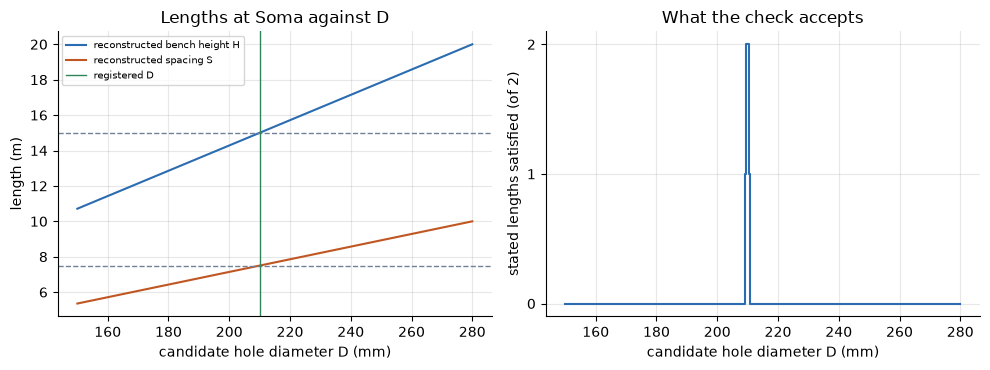

In [9]:
# Reconstructed bench height and spacing against the candidate diameter, and the statements met at each one
diameters, heights, spacings, met = (np.array(column) for column in zip(*sweep))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(diameters, heights, color="#2b6cb0", label="reconstructed bench height H")
left.plot(diameters, spacings, color="#c05621", label="reconstructed spacing S")
for _, stated_low, _ in registered.narrative:
    left.axhline(stated_low, color="#718096", lw=1, ls="--")
left.axvline(registered.hole_diameter_mm, color="#2f855a", lw=1, label="registered D")
left.set_xlabel("candidate hole diameter D (mm)")
left.set_ylabel("length (m)")
left.set_title("Lengths at Soma against D")
left.legend(fontsize=7)
right.step(diameters, met, where="mid", color="#2b6cb0")
right.set_yticks(range(len(registered.narrative) + 1))
right.set_xlabel("candidate hole diameter D (mm)")
right.set_ylabel("stated lengths satisfied (of 2)")
right.set_title("What the check accepts")
fig.tight_layout()
plt.show()

The left panel shows why: the reconstructed bench height and spacing both grow in proportion to the diameter, and each crosses its dashed line, the stated value, exactly at the registered diameter. The right panel shows the verdict: 2 of 2 stated lengths satisfied at the registered value and none anywhere else. The 175 mm reading in the registry note fails the bench height. The figure does not show that the check can choose between two readings that both fit the prose; at Soma it cannot test the burden, and at sites whose statements are wide ranges it would accept many more diameters.

### Step 6: where nothing fixes the scale

Miami publishes no hole diameter and no absolute length, so no honest reconstruction exists. The engine raises `GeometryUnavailable` instead of guessing, and `has_absolute_geometry` is the predicate that every predictor needing a volume uses to decide whether to answer. The first cell counts the blasts with a resolvable scale and catches the refusal. The second asks what a guess would cost: it registers for Miami, one at a time, diameters between the smallest (76 mm) and the largest (229 mm) used at the other sites, and reconstructs the rock volume of its six blasts.

In [10]:
# Ask the engine for the Miami scale: the refusal it raises and the count of blasts that do have a scale
miami = [b for b in train if b.site == "Miami"]
try:
    bf.reconstruct_pattern(miami[0])
except bf.GeometryUnavailable as refusal:
    print("engine refusal:", str(refusal)[:105], "...")
resolvable = sum(bf.has_absolute_geometry(b) for b in train)
print(f"blasts with a resolvable scale: {resolvable} of {len(train)}")
print("Miami blasts with a resolvable scale:", sum(bf.has_absolute_geometry(b) for b in miami))

engine refusal: Mi1: Miami Mine, Arizona, USA publishes no hole diameter and no absolute dimension, so its scale cannot b ...
blasts with a resolvable scale: 91 of 97
Miami blasts with a resolvable scale: 0


The engine refuses in words, naming the site and the missing information, and the count is 91 of 97: none of the six Miami blasts has a scale. Every predictor that needs a volume must abstain on them, and later notebooks show those abstentions in the benchmark. The refusal is a result, not a failure: the corpus contains a site on which the classical equation cannot be applied, and the engine says so.

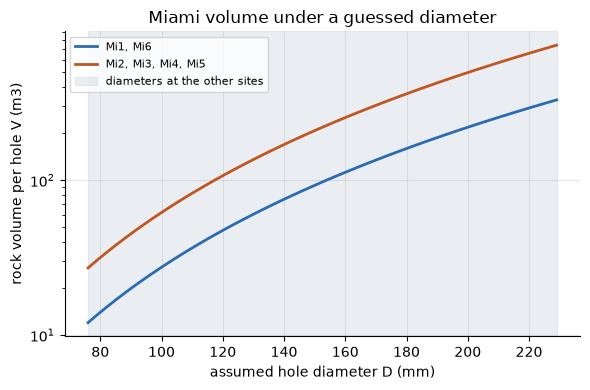

volume ratio between D = 229 and D = 76 mm: 27.4


In [11]:
# What a guessed Miami diameter would do: the rock volume of its six blasts for the diameters used at the other sites
diameters = np.arange(76.0, 230.0, 3.0)
volumes = []
for diameter in diameters:
    guess = dataclasses.replace(bf.SITE_GEOMETRY["Miami"], hole_diameter_mm=float(diameter))
    with patch.dict(bf.SITE_GEOMETRY, {"Miami": guess}):
        volumes.append([bf.reconstruct_pattern(b).rock_volume_m3 for b in miami])
volumes = np.array(volumes)
fig, ax = plt.subplots(figsize=(6, 4))
groups = {}
for column, blast in enumerate(miami):
    groups.setdefault(round(volumes[0, column], 1), []).append((column, blast.blast_id))
for color, members in zip(["#2b6cb0", "#c05621"], groups.values()):
    ax.plot(diameters, volumes[:, members[0][0]], lw=2, color=color, label=", ".join(name for _, name in members))
ax.axvspan(76, 229, color="#cbd5e0", alpha=0.4, label="diameters at the other sites")
ax.set_yscale("log")
ax.set_xlabel("assumed hole diameter D (mm)")
ax.set_ylabel("rock volume per hole V (m3)")
ax.set_title("Miami volume under a guessed diameter")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"volume ratio between D = 229 and D = 76 mm: {volumes[-1, 1] / volumes[0, 1]:.1f}")

A guessed diameter is not a small error. The rock volume per hole of the same Miami blasts follows a power law in the assumed diameter and differs by a factor of 27.4 between 76 mm and 229 mm, the two extremes in use at other sites; the explosive mass moves with it, and so would every classical prediction built on them. There are two curves because the six Miami blasts come in two geometries. The figure does not say which diameter is right. That is the point: nothing in the source does, so the engine refuses.

## Results

**Answer:** Yes, with one stored length per site. A registered hole diameter turns every ratio into metres by four multiplications, and it gives the 91 blasts of nine sites a rock volume of 17.6 to 675 m3 per hole. The conversion can be tested: all 15 lengths that the paper's prose states are met, and the test is not a formality, because at Soma the engine's check accepts only diameters from 209.6 to 210.4 mm. Where nothing fixes the scale (the six Miami blasts) the engine refuses, and a guess would move the rock volume by a factor of 27.4.

**What follows.** Every classical prediction of topic 02 inherits this registry: its volumes and masses are as good as the diameters, and each prediction can name where its diameter came from (quoted, derived or absent). The sites whose statements are single values are the best verified; the ones whose statements are wide ranges are verified only loosely.

**What this notebook does not show.** Matching the paper's prose proves that the lengths are consistent with what the authors wrote, not that they measured it correctly. The Reocin-UG diameter was derived from the bench height that the check then tests, so that one statement is met by construction. The check cannot choose between two readings that both satisfy the prose, and nothing here says how accurate any prediction made with these lengths will be.

## Summary

- One registered diameter per site turns every ratio into metres: four multiplications, a rock volume and an explosive mass.
- `verify_reconstruction` tests the result against the 15 lengths the paper's prose states, and all 15 are met.
- The check has power: at Soma it accepts a window of 0.8 mm around the registered diameter and nothing else in a sweep from 150 to 280 mm.
- Where no length is published (Miami) the engine refuses, a guess would change the volume by a factor of 27.4, and 91 of the 97 blasts remain usable by the classical predictors.
- Next: notebook 03 opens the integrity gate on the corpus itself and the negative control that the refusal feeds (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus, the site narratives and the printed ratios)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/